# Member 5: Retrieval Experiments (Name: Sze Xuan Yap; ID: 25763158)

This notebook evaluates the CrisisLens retrieval component. It imports the functions in `models/retrieval/` so the evaluated code is the same code the backend calls.

Run from the repository after the setup step, which builds the indexes:

>uv run python models/retrieval/build_index.py


Results are saved in `outputs/results/retrieval/`:

| File | Contents |
| --- | --- |
| `query_set.csv` | The test queries |
| `relevance_judgements.csv` | All manual relevance judgements (tuning and final) |
| `rankings.csv` | Every ranked result used for judging and metrics |
| `method_comparison.csv` | TF-IDF settings, final comparison, query time and size, and method selection |
| `duplicate_and_filter_checks.csv` | Duplicate threshold, duplicate behaviour and filter checks |


In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import pandas as pd

def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "models" / "retrieval").exists():
            return candidate
    raise FileNotFoundError("Run this notebook inside the CrisisLens repository.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from models.retrieval.build_index import HISTORY_PATH

RESULTS = PROJECT_ROOT / "outputs" / "results" / "retrieval"
for folder in [RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
history = pd.read_parquet(HISTORY_PATH)
history["words"] = history["text_display"].str.split().str.len()
print(f"Historical messages: {len(history):,}")

Historical messages: 76,484


## 1. Creation of Query Set

The queries, relevance criteria and evaluation rules were defined before examining the corresponding results. This prevents the results from influencing how the methods are evaluated or selected.

| Group | Number | Source | Use |
| --- | ---: | --- | --- |
| Tuning | 10 | Validation tweets, one per label | Choosing TF-IDF settings and checking the code |
| Final original | 20 | Test tweets, two per label | Final TF-IDF versus semantic comparison |
| Final paraphrased | 10 | One rewrite of an original test query per label | Same meaning in different words |
| Final search | 10 | Written by hand | Short keyword searches, with and without filters |

*The tweets used as search queries are left out of the messages being searched to avoid each query finding the same tweet as its first result.*

### 1.1 Definition of Judgement Rule

Each message returned for a query is read and judged manually as `relevant` (1) or `not relevant` (0), following the rule below. The judgements are used to calculate how many of each method's top results are relevant.

- **Relevant:** the message would be useful to show next to the query, as it concerns the same type of need, damage or situation (for example, another request for drinking water, or a report of a water shortage for a water request), or it is a copy of the query.
- **Not relevant:** a different topic, or only general disaster words in common (for example, a prayer message for a water request).
- Relevance depends on whether the humanitarian situation or the purpose of the message is related. A place mentioned in the query does not limit relevance, unless the query asks about that specific place (for example, a search for one location).
- The HumAID label is not used when judging, as some labels are inaccurate and one label covers many different situations.

### 1.2 Candidate Queries

Before the queries were chosen, the notebook drew a shortlist of tweets that could become queries:

- **For each label**: 3 tweets from the validation set, 5 from the test set, and 5 spare tweets ("reserves").
- **Checking the shortlist**: each tweet on the shortlist (a candidate) was checked against the checklist. It had to be in English, understandable on its own, like a real user report, clear enough to judge, and free of private information.
- **The final selection**: the tweets that passed became the actual queries listed in 1.3. If no tweet passed for a label, a reserve was used instead.

So the candidates are the shortlist, and the queries are the ones finally picked from it.

In [2]:
def draw_candidates(history: pd.DataFrame, split: str, per_label: int, seed: int = SEED) -> pd.DataFrame:
    pool = history[(history["split"] == split) & (history["words"] >= 3)]
    chosen = []
    for label, group in pool.groupby("board_label"):
        group = group.sample(frac=1, random_state=seed)
        picks, used_events, want_short = [], set(), True
        for i, row in group.iterrows():
            if row["event"] in used_events or (row["words"] < 10) != want_short:
                continue
            picks.append(i)
            used_events.add(row["event"])
            want_short = not want_short
            if len(picks) == per_label:
                break
        # Fill any gap when a label has too few events or lengths to alternate.
        for i in group.index:
            if len(picks) == per_label:
                break
            if i not in picks:
                picks.append(i)
        chosen.extend(picks)
    columns = ["id", "split", "board_label", "event", "words", "text_display"]
    return pool.loc[chosen, columns].reset_index(drop=True)

def draw_with_reserves(split: str, main: int, reserve: int = 5) -> pd.DataFrame:
    drawn = draw_candidates(history, split, per_label=main + reserve)
    drawn.insert(3, "reserve", drawn.groupby("board_label").cumcount() >= main)
    return drawn

candidates = pd.concat([
    draw_with_reserves("validation", main=3),
    draw_with_reserves("test", main=5),
], ignore_index=True)

print(candidates.groupby(["split", "board_label"]).size().unstack(0))

split                                   test  validation
board_label                                             
caution_and_advice                        10           8
displaced_people_and_evacuations          10           8
infrastructure_and_utility_damage         10           8
injured_or_dead_people                    10           8
missing_or_found_people                   10           8
not_humanitarian                          10           8
other_relevant_information                10           8
requests_or_urgent_needs                  10           8
rescue_volunteering_or_donation_effort    10           8
sympathy_and_support                      10           8


In [3]:
#Display the candidate list
candidates
#Download the list as csv
#candidates.to_csv(PROJECT_ROOT / "candidate_queries.csv", index=False)

,id,split,board_label,reserve,event,words,text_display
0,history-797793149116510208,validation,caution_and_advice,False,kaikoura_earthquake_2016,8,RT @3AW693: The latest official tsunami advice...
1,history-1167721367871119360,validation,caution_and_advice,False,hurricane_dorian_2019,35,📰 Todays Top News: 1. @realDonaldTrump Declare...
2,history-1176745748660183040,validation,caution_and_advice,False,pakistan_earthquake_2019,7,RT @AhmerJalil: Massive Earthquake in Northern...
3,history-783908275427414016,validation,caution_and_advice,True,hurricane_matthew_2016,15,Emergency workers struggle to reach worst-hit ...
4,history-1110349754305822726,validation,caution_and_advice,True,midwestern_us_floods_2019,9,Historic floods hit Nebraska after bomb cyclon...
...,...,...,...,...,...,...,...
175,history-907586490452070405,test,sympathy_and_support,True,hurricane_irma_2017,13,"More than 1,100 Marines are providing support ..."
176,history-721803967844511746,test,sympathy_and_support,True,ecuador_earthquake_2016,6,RT @ESM80903: Praying for Ecuador. #EquadorEar...
177,history-910560698689773568,test,sympathy_and_support,True,puebla_mexico_earthquake_2017,25,RT @SOMEXlCAN: Pray for Mexico 🇲🇽 City earthqu...
178,history-910555630808821760,test,sympathy_and_support,True,hurricane_maria_2017,8,Keeping Puerto Rico in my thoughts & prayers


### 1.3 Selected Queries

The shortlisted tweets that pass the checklist are selected as the queries below, with one validation tweet and two test tweets per label.

In [4]:
# 10 validation IDs, one per label.
TUNING_IDS = [
    "history-1036816130126610433",  # caution_and_advice (reserve)
    "history-1168146949926637568",  # displaced_people_and_evacuations
    "history-728644581038788608",   # infrastructure_and_utility_damage (reserve)
    "history-722023526685896705",   # injured_or_dead_people
    "history-1001192363719618561",  # missing_or_found_people
    "history-1167611347212931073",  # not_humanitarian
    "history-1110987364728557568",  # other_relevant_information
    "history-1030962909369827328",  # requests_or_urgent_needs
    "history-1022790474418012160",  # rescue_volunteering_or_donation_effort
    "history-1061135944126914560",  # sympathy_and_support
]

# 20 test IDs, two per label.
FINAL_IDS = [
    "history-1032586148860678144",  # caution_and_advice
    "history-1040547082409582592",  # caution_and_advice
    "history-1168230564912128000",  # displaced_people_and_evacuations
    "history-1039595158248058880",  # displaced_people_and_evacuations
    "history-903391663279755265",   # infrastructure_and_utility_damage
    "history-910534121914482693",   # infrastructure_and_utility_damage
    "history-1176825874701852673",  # injured_or_dead_people
    "history-783826569538273280",   # injured_or_dead_people
    "history-1001188720496672768",  # missing_or_found_people
    "history-1062857859090722816",  # missing_or_found_people
    "history-1111402647498547201",  # not_humanitarian
    "history-797862692769800192",   # not_humanitarian
    "history-907729306104852480",   # other_relevant_information
    "history-1110275496590348292",  # other_relevant_information (reserve)
    "history-1065696823984168961",  # requests_or_urgent_needs
    "history-1176556271639715841",  # requests_or_urgent_needs (reserve)
    "history-1031537210816778240",  # rescue_volunteering_or_donation_effort
    "history-909014170103898112",   # rescue_volunteering_or_donation_effort
    "history-1168296828829405185",  # sympathy_and_support
    "history-901835482014855168",   # sympathy_and_support
]

# Candidate ID -> reason for passing over it.
SKIPPED = {
    # Validation
    "history-797793149116510208": "refers to tsunami advice without stating it",
    "history-1167721367871119360": "several unrelated headlines in one message",
    "history-1176745748660183040": "reports the earthquake rather than giving advice; label appeared inconsistent with content",
    "history-783908275427414016": "reserve; reports the situation rather than giving advice",
    "history-1110349754305822726": "reserve; reports the floods rather than giving advice",
    "history-908352555876589569": "about a political visit; damage only mentioned",
    "history-902628106380476417": "about clothing rather than damage",
    "history-910687886445494273": "media headline without specific damage information",
    "history-1167807754393669637": "reserve; describes possible damage only",
    "history-1002942245430013954": "names a private individual (privacy)",
    "history-798004892820377600": "unclear meaning",
    "history-908320291696336896": "appeared to fit relief efforts better than its label",
    "history-1108262776189931522": "no specific content",
    "history-1040424546749362182": "too little content",
    # Test
    "history-1168231498555809794": "mixes several unrelated weather events",
    "history-1061449963454947329": "no detail beyond the heading",
    "history-913871597215342592": "about a damage map rather than the damage",
    "history-907985502741188608": "reports that there was no damage",
    "history-1168252684090187779": "too broad; unclear what was damaged",
    "history-1064491487902224384": "mainly a boycott call",
    "history-1065464052590161920": "celebrity story; label appeared inconsistent with content",
    "history-1001245514183135232": "same news story as another selected query",
    "history-797978456214540288": "a sympathy message; label appeared inconsistent with content",
    "history-911599018991603712": "conspiracy content",
    "history-1176469477237690368": "describes media content rather than a situation",
    "history-1168357526410280960": "too vague",
    "history-903412449407324160": "no specific content",
    "history-911754981824434177": "a complaint rather than a request",
    "history-1032071865643151360": "does not state the help needed",
    "history-1030768680584601601": "contains a private individual's name, location and phone number (privacy)",
}

### 1.4 Paraphrases and Search Queries

- **Paraphrased queries**: to test whether a method still finds related messages when the same meaning is written in different words.
- **Search queries**: to test `search()` with short keywords, with and without filters.

Paraphrase judgements are reused from the original query where the same message is returned. Location filters are tested on user reports in Section 5.4.

In [5]:
# Final original query ID (from FINAL_IDS) -> paraphrased text, one per label.
PARAPHRASES = {
    "history-1032586148860678144": "Advice on staying safe on the road when streets are under water",
    "history-1168230564912128000": "People in two districts have been told they must leave their homes, and emergency accommodation is now open",
    "history-903391663279755265": "Roughly one hundred thousand houses were harmed by the hurricane",
    "history-1176825874701852673": "The earthquake killed dozens of people and injured hundreds.",
    "history-1001188720496672768": "Authorities are searching for a man missing since floodwater swept through the town.",
    "history-1111402647498547201": "An old photograph shows a young woman posing with a tornado behind her.",
    "history-907729306104852480": "The storm dropped more than half a metre of rain on the island",
    "history-1065696823984168961": "Essential items for children are urgently needed.",
    "history-1031537210816778240": "Five million dollars in aid has been pledged to help communities hit by the floods.",
    "history-1168296828829405185": "My heart goes out to everyone affected, hoping help reaches them quickly",
}

# Short search queries and their filters (query text, filters).
SEARCH_QUERIES = [
    ("clean water needed", {}),
    ("collapsed bridge", {}),
    ("missing child", {}),
    ("evacuation warning", {}),
    ("medical supplies", {}),
    ("volunteers needed", {}),
    ("power outage", {"board_label": "infrastructure_and_utility_damage"}),
    ("donate", {"board_label": "rescue_volunteering_or_donation_effort"}),
    ("flooding", {"created_after": "2018-08-01", "created_before": "2018-09-30"}),
    ("", {"board_label": "missing_or_found_people"}),
]

### 1.5 Save the Query Set

The cell checks that every group is complete before saving `outputs/results/retrieval/query_set.csv`.

In [6]:
RARE_LABELS = {"missing_or_found_people", "requests_or_urgent_needs"}

def query_type(label: str | None, words: int) -> str:
    if label in RARE_LABELS:
        return "rare_category"
    return "short" if words < 10 else "standard"

def original_rows(ids: list[str], query_set: str, prefix: str) -> list[dict]:
    rows = []
    for n, source_id in enumerate(ids, start=1):
        source = history.set_index("id").loc[source_id]
        rows.append({
            "query_id": f"{prefix}{n:02d}",
            "query_set": query_set,
            "query_origin": "original",
            "query_type": query_type(source["board_label"], source["words"]),
            "parent_query_id": None,
            "query_text": source["text_display"],
            "source_id": source_id,
            "source_label": source["board_label"],
            "source_event": source["event"],
            "split": source["split"],
            "filters_json": json.dumps({}),
            "notes": None,
        })
    return rows

problems = []
if len(TUNING_IDS) != 10:
    problems.append(f"TUNING_IDS has {len(TUNING_IDS)} IDs, expected 10")
if len(FINAL_IDS) != 20:
    problems.append(f"FINAL_IDS has {len(FINAL_IDS)} IDs, expected 20")
if len(PARAPHRASES) != 10:
    problems.append(f"PARAPHRASES has {len(PARAPHRASES)} entries, expected 10")
if len(SEARCH_QUERIES) != 10:
    problems.append(f"SEARCH_QUERIES has {len(SEARCH_QUERIES)} entries, expected 10")

if problems:
    print("Query set not saved yet:")
    for problem in problems:
        print(" -", problem)
else:
    lookup = history.set_index("id")
    assert set(lookup.loc[TUNING_IDS, "split"]) == {"validation"}, "TUNING_IDS must be validation tweets"
    assert set(lookup.loc[FINAL_IDS, "split"]) == {"test"}, "FINAL_IDS must be test tweets"
    assert lookup.loc[TUNING_IDS, "board_label"].nunique() == 10, "TUNING_IDS need one tweet per label"
    assert (lookup.loc[FINAL_IDS, "board_label"].value_counts() == 2).all(), "FINAL_IDS need two tweets per label"
    assert set(PARAPHRASES) <= set(FINAL_IDS), "PARAPHRASES keys must be FINAL_IDS"
    assert set(TUNING_IDS + FINAL_IDS + list(SKIPPED)) <= set(candidates["id"]), "Every ID must be a drawn candidate"
    assert not set(SKIPPED) & set(TUNING_IDS + FINAL_IDS), "A selected ID is also listed as skipped"

    rows = original_rows(TUNING_IDS, "tuning", "T") + original_rows(FINAL_IDS, "final_retrieval", "F")
    parent_query = {row["source_id"]: row for row in rows if row["query_set"] == "final_retrieval"}
    for n, (source_id, text) in enumerate(PARAPHRASES.items(), start=1):
        parent = parent_query[source_id]
        rows.append({
            **parent,
            "query_id": f"P{n:02d}",
            "query_origin": "paraphrased",
            "query_type": query_type(parent["source_label"], len(text.split())),
            "parent_query_id": parent["query_id"],
            "query_text": text,
        })
    for n, (text, filters) in enumerate(SEARCH_QUERIES, start=1):
        rows.append({
            "query_id": f"S{n:02d}",
            "query_set": "final_search",
            "query_origin": "handwritten",
            "query_type": "search",
            "parent_query_id": None,
            "query_text": text,
            "source_id": None,
            "source_label": None,
            "source_event": None,
            "split": None,
            "filters_json": json.dumps(filters),
            "notes": None,
        })

    query_set = pd.DataFrame(rows)
    query_set.to_csv(RESULTS / "query_set.csv", index=False)
    print(f"Saved {len(query_set)} queries to {(RESULTS / 'query_set.csv').relative_to(PROJECT_ROOT)}")
    print(query_set.groupby(["query_set", "query_origin"]).size())

Saved 50 queries to outputs/results/retrieval/query_set.csv
query_set        query_origin
final_retrieval  original        20
                 paraphrased     10
final_search     handwritten     10
tuning           original        10
dtype: int64


## 2. Choosing the TF-IDF Settings

Two settings are compared on the 10 tuning queries:

| Setting | Terms | Other settings |
| --- | --- | --- |
| L1 (unigram) | Single words | `min_df=2`, `sublinear_tf=True`, L2 normalisation |
| L2 (unigram + bigram) | Single words and two-word pairs | Same as L1 |

*L1 and L2 are labels for the two settings, not referring to L1 or L2 normalisation, as both settings use L2 normalisation.*

Both are fitted on **training tweets only**, so the validation queries are never part of the index they search. The top 10 results of both settings for each tuning query are judged relevant (1) or not relevant (0) with the rule in Section 1.1, without seeing which setting returned them.

**Decision rule:**

1. Select the setting with the higher manual Precision@10.
2. If the difference is under 0.05, select L1 (unigram), as it is smaller and simpler.

In [7]:
from models.retrieval.evaluate import (
    SETTING_NAMES, TFIDF_SETTINGS, build_tfidf_index, judgement_sheet,
    precision_at_k, rank_tfidf, rankings_table,
    collect_judgements, long_rows, save_rows,
)

JUDGEMENTS_FILE = RESULTS / "relevance_judgements.csv"

if "query_set" not in globals():
    query_set = pd.read_csv(RESULTS / "query_set.csv")
tuning_queries = query_set[query_set["query_set"] == "tuning"].reset_index(drop=True)

### 2.1 Build Both Indexes on Training Tweets

In [8]:
tuning_indexes = {name: build_tfidf_index(history, ["train"], settings) for name, settings in TFIDF_SETTINGS.items()}

index_summary = pd.DataFrame({
    name: {
        "messages": index["messages"],
        "vocabulary": index["vocabulary"],
        "build_seconds": round(index["build_seconds"], 2),
        "size_mb": round(index["size_mb"], 1),
    }
    for name, index in tuning_indexes.items()
}).T
index_summary

,messages,vocabulary,build_seconds,size_mb
L1,53531.0,20242.0,0.47,12.6
L2,53531.0,113949.0,1.38,24.1


### 2.2 Tuning Rankings and Judgements

The tuning judgements are recorded in `relevance_judgements.csv`. A ranked message without a judgement is added to that file with an empty `relevant` cell, once per query, in random order and without the setting name or similarity score.

In [9]:
tuning_results = {
    name: {q.query_id: rank_tfidf(index, q.query_text, k=10) for q in tuning_queries.itertuples()}
    for name, index in tuning_indexes.items()
}
tuning_rankings = rankings_table(tuning_results)
save_rows(RESULTS / "rankings.csv", tuning_rankings.assign(stage="tuning"), key="stage")

*_, tuning_status = collect_judgements("tuning", tuning_rankings, tuning_queries, JUDGEMENTS_FILE, SEED)
print(tuning_status)
overlap = tuning_rankings.groupby("query_id")["doc_id"].apply(lambda s: s.duplicated().sum())
print(f"Messages returned by both settings: {overlap.sum()}")

Using 163 tuning judgements from relevance_judgements.csv.
Messages returned by both settings: 37


### 2.3 Manual Precision and the Decision

In [10]:
judgements, remaining, _, tuning_status = collect_judgements("tuning", tuning_rankings, tuning_queries, JUDGEMENTS_FILE, SEED)

if remaining:
    print(tuning_status)
else:
    tuning_precision = precision_at_k(tuning_rankings, judgements)
    manual_summary = tuning_precision.groupby("method")[["precision@5", "precision@10"]].mean()
    display(manual_summary.round(3))
    display(tuning_precision.pivot(index="query_id", columns="method", values="precision@10"))

    manual_gap = round(manual_summary.loc["L2", "precision@10"] - manual_summary.loc["L1", "precision@10"], 3)
    if abs(manual_gap) >= 0.05:
        chosen, reason = ("L2" if manual_gap > 0 else "L1"), "manual Precision@10"
    else:
        chosen, reason = "L1", "difference under 0.05; the smaller, simpler setting"
    print(f"Manual Precision@10 gap (L2 - L1): {manual_gap:+.3f}")
    print(f"Selected setting: {chosen} (decided by {reason})")

,precision@5,precision@10
method,,
L1,0.64,0.63
L2,0.72,0.65


method,L1,L2
query_id,,
T01,0.2,0.6
T02,0.7,0.8
T03,0.5,0.4
T04,0.7,1.0
T05,1.0,1.0
T06,0.7,0.7
T07,0.6,0.2
T08,0.5,0.4
T09,0.6,0.7


Manual Precision@10 gap (L2 - L1): +0.020
Selected setting: L1 (decided by difference under 0.05; the smaller, simpler setting)


### 2.4 Save the Comparison

In [11]:
if remaining:
    print("Finish the judgement sheet and rerun 2.3 first.")
else:
    comparison = index_summary.join(manual_summary)
    comparison["selected"] = (comparison.index == chosen).astype(int)
    comparison.index.name = "setting"
    save_rows(RESULTS / "method_comparison.csv", long_rows(comparison, "tfidf_settings"), key="experiment")

    comparison_view = pd.DataFrame({
        "Vocabulary": comparison["vocabulary"].astype(int),
        "Size (MB)": comparison["size_mb"],
        "Precision@5": comparison["precision@5"].round(2),
        "Precision@10": comparison["precision@10"].round(2),
        "Selected": ["Yes" if selected else "No" for selected in comparison["selected"]],
    }).rename(index=SETTING_NAMES)
    comparison_view.index.name = "Configuration"
    display(comparison_view)

,Vocabulary,Size (MB),Precision@5,Precision@10,Selected
Configuration,,,,,
Unigram,20242,12.6,0.64,0.63,Yes
Unigram + bigram,113949,24.1,0.72,0.65,No


## 3. Semantic Retrieval Setup

In this section, semantic retrieval is set up as the alternative to TF-IDF for `retrieve()`.

- **Method:** semantic retrieval represents each message as 384 numbers describing its meaning. As a result, messages with a similar meaning are placed close together even when they share few words.
- **Model:** one compact pretrained model, namely `all-MiniLM-L6-v2`, is adopted without fine-tuning. It runs on the CPU, making its query time comparable with TF-IDF.
- **Default method:** TF-IDF remains the default in `retrieve()` until the final comparison in Section 4, while `search()`, which is designed for keyword searching, uses TF-IDF throughout.
- **Controlled comparison:** both final-evaluation indexes hold the same training and validation messages with the same cleaned text, and the test queries are kept out of both indexes.
- **Scope:** this section only verifies that both methods work, using three tuning queries and one written message. No final query is run before Section 4.



### 3.1 Load the Model

In [12]:
import platform
import time
from importlib.metadata import version

import torch

from models.retrieval.evaluate import build_semantic_index, rank_semantic
from models.retrieval.build_index import BATCH_SIZE, DEVICE, MODEL_NAME, load_model

start = time.perf_counter()
model = load_model()
model_load_seconds = time.perf_counter() - start

environment = pd.Series({
    "model": MODEL_NAME,
    "embedding dimension": model.encode(["test"]).shape[1],
    "device": DEVICE,
    "batch size": BATCH_SIZE,
    "model load seconds": round(model_load_seconds, 2),
    "sentence-transformers": version("sentence-transformers"),
    "torch": version("torch"),
    "machine": f"{platform.machine()} {platform.processor()}".strip(),
    "CPU threads used": torch.get_num_threads(),
})
environment

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

model                    sentence-transformers/all-MiniLM-L6-v2
embedding dimension                                         384
device                                                      cpu
batch size                                                   64
model load seconds                                         8.05
sentence-transformers                                     6.1.0
torch                                                    2.14.1
machine                                               arm64 arm
CPU threads used                                              4
dtype: object

### 3.2 Build the Final-Evaluation Indexes

The TF-IDF configuration selected in Section 2 is loaded from `method_comparison.csv`. A separate search index uses `min_df=1`, which retains words that appear in only one message and allows uncommon names to be searched.

In [13]:
from models.retrieval.build_index import SEARCH_SETTINGS

comparison_file = pd.read_csv(RESULTS / "method_comparison.csv")
SELECTED_TFIDF = comparison_file.query(
    "experiment == 'tfidf_settings' and measure == 'selected' and value == 1"
)["method"].iloc[0]
print(f"Selected TF-IDF setting: {SELECTED_TFIDF} ({SETTING_NAMES[SELECTED_TFIDF].lower()})")

final_tfidf = build_tfidf_index(history, ["train", "validation"], TFIDF_SETTINGS[SELECTED_TFIDF])
final_search_tfidf = build_tfidf_index(history, ["train", "validation"], SEARCH_SETTINGS)  # for search(), every word kept
print(f"Search index (every word kept): {final_search_tfidf['vocabulary']:,} words, {final_search_tfidf['size_mb']:.1f} MB")
final_semantic = build_semantic_index(final_tfidf, model)

final_index_summary = pd.DataFrame({
    f"TF-IDF ({SETTING_NAMES[SELECTED_TFIDF].lower()})": {
        "messages": final_tfidf["messages"],
        "features": final_tfidf["vocabulary"],
        "build_seconds": round(final_tfidf["build_seconds"], 2),
        "size_mb": round(final_tfidf["size_mb"], 1),
    },
    "Semantic": {
        "messages": final_semantic["messages"],
        "features": final_semantic["dimension"],
        "build_seconds": round(final_semantic["build_seconds"], 2),
        "size_mb": round(final_semantic["size_mb"], 1),
    },
}).T
final_index_summary

Selected TF-IDF setting: L1 (unigram)
Search index (every word kept): 49,498 words, 15.4 MB


Batches:   0%|          | 0/959 [00:00<?, ?it/s]

,messages,features,build_seconds,size_mb
TF-IDF (unigram),61324.0,21878.0,0.58,14.4
Semantic,61324.0,384.0,123.48,94.2


### 3.3 Check Both Methods

This check uses three tuning queries and one manually written rewording of T08. Tuning queries are validation tweets, which are now part of the index, so each query's own tweet is excluded from its results. Each table shows the full messages, and messages returned by both methods are highlighted.

In [14]:
import html

SHARED_COLOUR = "#fff3c4"
full_text = final_tfidf["records"].set_index("id")["text_display"]

def side_by_side(text: str, exclude_ids=None, k: int = 5):
    results = {
        "TF-IDF": rank_tfidf(final_tfidf, text, k, exclude_ids=exclude_ids),
        "Semantic": rank_semantic(final_semantic, text, k, model, exclude_ids=exclude_ids),
    }
    shared = {r["id"] for r in results["TF-IDF"]} & {r["id"] for r in results["Semantic"]}
    rows, flags = [], []
    for rank in range(k):
        row, flag = {("", "Rank"): rank + 1}, {}
        for name, ranked in results.items():
            r = ranked[rank] if rank < len(ranked) else None
            row[(name, "Score")] = r["similarity"] if r else None
            row[(name, "Message")] = full_text[r["id"]] if r else ""
            flag[name] = bool(r) and r["id"] in shared
        rows.append(row)
        flags.append(flag)
    table = pd.DataFrame(rows)
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table, pd.DataFrame(flags), len(shared)

def styled(text: str, exclude_ids=None, k: int = 5):
    table, flags, shared_count = side_by_side(text, exclude_ids, k)

    def highlight(frame: pd.DataFrame) -> pd.DataFrame:
        styles = pd.DataFrame("", index=frame.index, columns=frame.columns)
        for name in flags.columns:
            for column in ("Score", "Message"):
                styles.loc[flags[name].to_numpy(), (name, column)] = f"background-color: {SHARED_COLOUR}; color: black"
        return styles

    score_columns = [("TF-IDF", "Score"), ("Semantic", "Score")]
    message_columns = [("TF-IDF", "Message"), ("Semantic", "Message")]
    return (
        table.style
        .apply(highlight, axis=None)
        .format("{:.2f}", subset=score_columns, na_rep="")
        .format(escape="html", subset=message_columns)
        .set_properties(subset=message_columns, **{"white-space": "pre-wrap", "text-align": "left", "min-width": "320px"})
        .hide(axis="index")
        .set_caption(
            f"<b>Query:</b> {html.escape(text)}<br>"
            f"Found by both methods: {shared_count} of {k} (highlighted)<br>"
            "Scores are not comparable between the two methods."
        )
        .set_table_styles([
            {"selector": "caption", "props": "caption-side: top; text-align: left; padding: 8px 0;"},
            {"selector": "th.col_heading.level0", "props": "text-align: center;"},
            {"selector": "th.col_heading.level1.col2", "props": "text-align: left;"},
            {"selector": "th.col_heading.level1.col4", "props": "text-align: left;"},
        ])
    )

checks = [
    (q.query_text, [q.source_id]) for q in tuning_queries.set_index("query_id").loc[["T02", "T04", "T08"]].itertuples()
] + [("Lots of drinking water and meals will be needed for flood victims", None)]

for text, exclude in checks:
    display(styled(text, exclude_ids=exclude))

## 4. Evaluation of retrieve() and search()

In this section, TF-IDF and semantic retrieval are compared on the test queries to select the method for `retrieve()`, while `search()` is evaluated on its own.

- **Same conditions:** both methods search the same 61,324 training and validation messages, with the same queries, filters, duplicate rule and judgements. No test query is part of the messages being searched.
- **Method comparison:** 20 original and 10 paraphrased test queries are run with `retrieve()` using both methods, to select the method for related reports.
- **Search quality:** 9 search queries (S01 to S09) are run with `search()`, to measure the quality of keyword search. `search()` is not compared, as it is designed for keyword searching and adopts TF-IDF to ensure that every result contains at least one of the typed words.
- **Empty search:** S10, an empty search with a board filter, lists messages from newest to oldest. It is not judged, and its filter is checked in Section 5.4.

**Selection rule for `retrieve()`:** semantic retrieval is selected only when all three conditions hold. Otherwise, TF-IDF is kept.

1. Its mean Precision@5 over the 30 queries is at least 0.05 higher than TF-IDF's.
2. Its mean Precision@5 is at least as high as TF-IDF's in at least 6 of the 10 labels.
3. Its mean query time is 200 ms or less.

Precision@5 is the primary metric, as users are expected to read only the first few related reports. The model loading time is excluded from the query time, as the model is loaded only once when the application starts.

### 4.1 Results for Each Test Query
Each test query is run, and its top 20 results are saved to rankings.csv to include manual judgment. 

In [15]:
import numpy as np

from models.retrieval.evaluate import pooled_sheet, resolve_judgements, retrieval_metrics, time_queries

POOL_DEPTH = 20
query_set = pd.read_csv(RESULTS / "query_set.csv")
retrieval_queries = query_set[query_set["query_set"] == "final_retrieval"].reset_index(drop=True)
search_queries = query_set[
    (query_set["query_set"] == "final_search") & query_set["query_text"].fillna("").str.strip().ne("")
].reset_index(drop=True)
final_queries = pd.concat([retrieval_queries, search_queries], ignore_index=True)

def rank_query(query) -> dict[str, list[dict]]:
    filters = json.loads(query.filters_json) if isinstance(query.filters_json, str) else {}
    if query.query_set == "final_search":
        # search() is designed for keyword searching: TF-IDF with every word kept, grouped as in the app.
        return {"tfidf": rank_tfidf(final_search_tfidf, query.query_text, POOL_DEPTH, filters=filters,
                                    group_matrix=final_tfidf["matrix"])}
    return {
        "tfidf": rank_tfidf(final_tfidf, query.query_text, POOL_DEPTH, filters=filters),
        "semantic": rank_semantic(final_semantic, query.query_text, POOL_DEPTH, model, filters=filters),
    }

ranked = {q.query_id: rank_query(q) for q in final_queries.itertuples()}
final_rankings = rankings_table({
    method: {query_id: results[method] for query_id, results in ranked.items() if method in results}
    for method in ["tfidf", "semantic"]
})
final_rankings = final_rankings.merge(final_queries[["query_id", "query_set"]], on="query_id")
save_rows(RESULTS / "rankings.csv", final_rankings.assign(stage="final"), key="stage")

saved_counts = final_rankings.groupby(["query_set", "method"]).agg(
    Queries=("query_id", "nunique"), **{"Results saved": ("doc_id", "size")}
).reset_index()
saved_counts.insert(0, "Function", saved_counts.pop("query_set").map({"final_retrieval": "retrieve()", "final_search": "search()"}))
saved_counts["method"] = saved_counts["method"].map({"semantic": "Semantic", "tfidf": "TF-IDF"})
display(
    saved_counts.rename(columns={"method": "Method"}).style.hide(axis="index")
    .set_caption(f"Results saved to rankings.csv (top {POOL_DEPTH} per query)")
    .set_table_styles([{"selector": "caption", "props": "caption-side: top; text-align: left; padding: 8px 0; font-weight: bold;"}])
)

Function,Method,Queries,Results saved
retrieve(),Semantic,30,600
retrieve(),TF-IDF,30,600
search(),TF-IDF,9,180


### 4.2 Judgements

Ranked messages without a judgement are added to `relevance_judgements.csv` with an empty `relevant` cell, in random order and without the method, rank or score.

- **Retrieval queries:** judged with the rule in Section 1.1.
- **Search queries:** a message is relevant when it is about the searched topic.
- **Paraphrased queries:** a message already judged for the original query reuses that judgement, marked in `reused_from`.

In [16]:
final_judgements, final_remaining, reused_count, final_status = collect_judgements(
    "final", final_rankings, final_queries, JUDGEMENTS_FILE, SEED
)
print(final_status)

Using 1264 final judgements from relevance_judgements.csv.


### 4.3 Query Time and Resources

In this section, the time each method takes to answer a query is measured.

- **Timing**: each of the 39 final queries is run five times with each method, and the average time is reported. The first query is run once before the timing starts and is not counted, as the first run of a method can be slower than the rest.
- **What is timed**: turning the query into numbers, finding the top 10 results and grouping the copies, in the same way as the application.
- **Other columns**: the build time, index size and model loading time are taken from Section 3.

In [17]:
texts = final_queries["query_text"].tolist()
timings = {
    "TF-IDF": time_queries(lambda t: rank_tfidf(final_tfidf, t, 10), texts),
    "Semantic": time_queries(lambda t: rank_semantic(final_semantic, t, 10, model), texts),
}
latency = pd.DataFrame({
    name: {
        "mean_query_ms": times.mean(),
        "timed_queries": len(times),
    }
    for name, times in timings.items()
}).T
latency["build_seconds"] = final_index_summary["build_seconds"].to_numpy()
latency["size_mb"] = final_index_summary["size_mb"].to_numpy()
latency["model_load_seconds"] = [0.0, round(model_load_seconds, 2)]
latency["hardware"] = environment["machine"]
latency.index.name = "method"
save_rows(RESULTS / "method_comparison.csv", long_rows(latency.drop(columns="hardware"), "query_time_and_cost"), key="experiment")

# Show only the columns that differ between the methods (TF-IDF has no model to load).
latency_view = pd.DataFrame({
    "Mean query time (ms)": latency["mean_query_ms"].round(2),
    "Index build time (s)": latency["build_seconds"].round(2),
    "Index size (MB)": latency["size_mb"].round(1),
    "Model load time (s)": latency["model_load_seconds"].round(2).where(latency.index == "Semantic"),
}).rename_axis("Method")
latency_view.style.format(precision=2, na_rep="–").format("{:.1f}", subset=["Index size (MB)"])

,Mean query time (ms),Index build time (s),Index size (MB),Model load time (s)
Method,,,,
TF-IDF,28.05,0.58,14.4,–
Semantic,33.97,123.48,94.2,8.05


### 4.4 Precision and Pooled Recall

- **Precision@5 and Precision@10**: the share of a method's top 5 (or top 10) results that are relevant.
- **Pooled Recall@5 and Recall@10**: the share of all relevant messages found by either method that appear in a method's top 5 (or top 10). They are reported for retrieval queries only.

In [18]:
final_judgements, final_remaining, reused_count, final_status = collect_judgements(
    "final", final_rankings, final_queries, JUDGEMENTS_FILE, SEED
)

if final_remaining:
    print(final_status)
else:
    by_query = retrieval_metrics(final_rankings, final_judgements).merge(
        query_set[["query_id", "query_set", "query_origin", "query_type", "source_label"]], on="query_id"
    )
    metric_columns = ["precision@5", "precision@10", "pooled_recall@5", "pooled_recall@10"]

    def summarise(frame: pd.DataFrame, group: str, by: str | None = None) -> pd.DataFrame:
        keys = ["method"] + ([by] if by else [])
        table = frame.groupby(keys)[metric_columns].mean().reset_index()
        table.insert(0, "group", group)
        return table.rename(columns={by: "subgroup"}) if by else table.assign(subgroup="all")

    primary = by_query[by_query["query_set"] == "final_retrieval"]
    secondary = by_query[by_query["query_set"] == "final_search"]
    metrics = pd.concat([
        summarise(primary, "retrieval"),
        summarise(primary, "retrieval by origin", "query_origin"),
        summarise(primary, "retrieval by type", "query_type"),
        summarise(primary, "retrieval by category", "source_label"),
        # search() is TF-IDF only, so its pool holds TF-IDF results alone and pooled recall is left out.
        summarise(secondary, "search").drop(columns=["pooled_recall@5", "pooled_recall@10"]),
    ], ignore_index=True)
    paired = primary.pivot_table(index="query_id", columns="method", values="precision@5")
    paired["result"] = np.select(
        [paired["semantic"] > paired["tfidf"], paired["semantic"] < paired["tfidf"]],
        ["semantic better", "TF-IDF better"], "tie",
    )
    counts = paired["result"].value_counts()

    final_rows = metrics.melt(id_vars=["group", "method", "subgroup"], var_name="measure", value_name="value").dropna(subset=["value"])
    count_rows = [
        {"group": "retrieval", "subgroup": "all", "method": method,
         "measure": "queries better on precision@5", "value": counts.get(label, 0)}
        for method, label in [("semantic", "semantic better"), ("tfidf", "TF-IDF better"), ("tie", "tie")]
    ]
    final_rows = pd.concat([final_rows, pd.DataFrame(count_rows)], ignore_index=True).assign(experiment="final_comparison")
    final_rows = pd.concat([final_rows, pd.DataFrame([{
        "experiment": "final_comparison", "group": "judging", "subgroup": "all", "method": "both",
        "measure": "judgements reused from original queries", "value": reused_count,
    }])], ignore_index=True)
    save_rows(RESULTS / "method_comparison.csv", final_rows, key="experiment")

    print(f"Judgements reused from original queries: {reused_count}")
    for query_id in by_query.loc[by_query["pool_relevant"] == 0, "query_id"].unique():
        print(f"{query_id} is left out of pooled recall, as none of its judged results is relevant.")

Judgements reused from original queries: 36
P06 is left out of pooled recall, as none of its judged results is relevant.


In [19]:
from IPython.display import HTML, display
import pandas as pd

# Style used for all tables
TABLE_STYLE = [
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
        ],
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
        ],
    },
]


if final_remaining:
    print("Finish the judgement sheet and rerun the previous cell first.")

else:
    # =========================================================
    # 1. Overall retrieval and search performance
    # =========================================================
    overall = metrics[
        metrics["group"].isin(["retrieval", "search"])
    ].copy()

    query_numbers = {
        "retrieval": primary["query_id"].nunique(),
        "search": secondary["query_id"].nunique(),
    }

    main_table = pd.DataFrame({
        "Function": overall["group"].map({
            "retrieval": "retrieve()",
            "search": "search()",
        }),
        "Method": overall["method"].map({
            "semantic": "Semantic",
            "tfidf": "TF-IDF",
        }),
        "Queries": overall["group"].map(query_numbers),
        "Precision@5": overall["precision@5"],
        "Precision@10": overall["precision@10"],
        "Pooled Recall@5": overall["pooled_recall@5"],
        "Pooled Recall@10": overall["pooled_recall@10"],
    })

    display(
        HTML(
            """
            <h3>Overall retrieval and search performance</h3>
            <p style="margin: 0 0 8px 0;">
                Compares the overall effectiveness of the retrieval and
                search methods.
            </p>
            """
        )
    )

    display(
        main_table.style
        .hide(axis="index")
        .format(
            "{:.3f}",
            subset=[
                "Precision@5",
                "Precision@10",
                "Pooled Recall@5",
                "Pooled Recall@10",
            ],
            na_rep="–",
        )
        .set_table_styles(TABLE_STYLE)
    )

    # =========================================================
    # 2. Performance by query wording
    # =========================================================
    origin = (
        metrics[
            metrics["group"] == "retrieval by origin"
        ]
        .pivot_table(
            index="subgroup",
            columns="method",
            values=["precision@5", "precision@10"],
        )
    )

    query_counts = (
        primary
        .groupby("query_origin")["query_id"]
        .nunique()
    )

    origin_table = pd.DataFrame({
        "Queries": query_counts,
        "P@5 TF-IDF": origin[("precision@5", "tfidf")],
        "P@5 Semantic": origin[("precision@5", "semantic")],
        "P@10 TF-IDF": origin[("precision@10", "tfidf")],
        "P@10 Semantic": origin[("precision@10", "semantic")],
    })

    origin_table = (
        origin_table
        .rename(
            index={
                "original": "Original queries",
                "paraphrased": "Paraphrased queries",
            }
        )
        .rename_axis(None)
    )

    display(
        HTML(
            """
            <h3>Performance by query wording</h3>
            <p style="margin: 0 0 8px 0;">
                Examines whether performance changes when the same meaning
                is expressed using different words.
            </p>
            """
        )
    )

    display(
        origin_table.style
        .format(
            "{:.3f}",
            subset=[
                "P@5 TF-IDF",
                "P@5 Semantic",
                "P@10 TF-IDF",
                "P@10 Semantic",
            ],
        )
        .set_table_styles(TABLE_STYLE)
    )

    # =========================================================
    # 3. Query-level Precision@5 comparison
    # =========================================================
    comparison_counts = counts.reindex(
        [
            "semantic better",
            "tie",
            "TF-IDF better",
        ],
        fill_value=0,
    )

    query_table = pd.DataFrame({
        "Semantic higher": [
            int(comparison_counts["semantic better"])
        ],
        "Same": [
            int(comparison_counts["tie"])
        ],
        "TF-IDF higher": [
            int(comparison_counts["TF-IDF better"])
        ],
    })

    display(
        HTML(
            """
            <h3>Query-level Precision@5 comparison</h3>
            <p style="margin: 0 0 8px 0;">
                Shows which method did better on each of the 30 retrieval queries.
            </p>
            """
        )
    )

    display(
        query_table.style
        .hide(axis="index")
        .set_table_styles(TABLE_STYLE)
    )

Function,Method,Queries,Precision@5,Precision@10,Pooled Recall@5,Pooled Recall@10
retrieve(),Semantic,30,0.800,0.773,0.191,0.354
retrieve(),TF-IDF,30,0.607,0.577,0.161,0.269
search(),TF-IDF,9,0.756,0.733,–,–


,Queries,P@5 TF-IDF,P@5 Semantic,P@10 TF-IDF,P@10 Semantic
Original queries,20,0.650,0.790,0.600,0.760
Paraphrased queries,10,0.520,0.820,0.530,0.800


Semantic higher,Same,TF-IDF higher
16,10,4


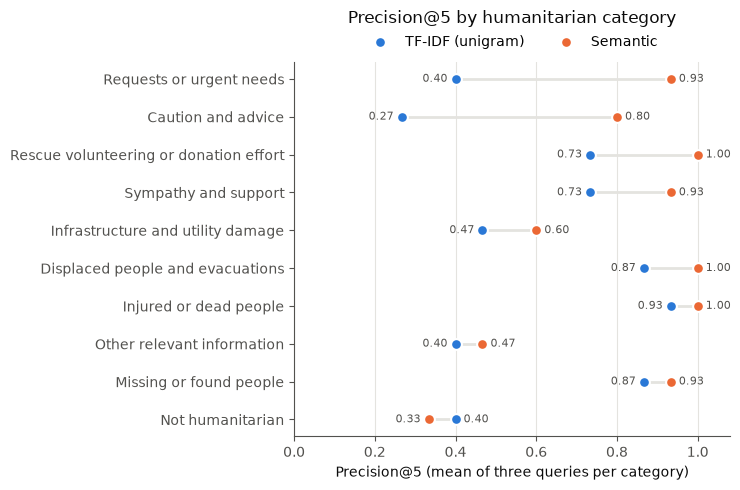

In [20]:
import matplotlib.pyplot as plt

LABELS = {"tfidf": f"TF-IDF ({SETTING_NAMES[SELECTED_TFIDF].lower()})", "semantic": "Semantic"}
COLOURS = {"tfidf": "#2a78d6", "semantic": "#eb6834"}
ORIGIN_STYLE = {"original": ("#52514e", "o"), "paraphrased": ("#1baf7a", "^")}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white",
})

def plot_by_category() -> None:
    by_category = metrics[metrics["group"] == "retrieval by category"].pivot_table(
        index="subgroup", columns="method", values="precision@5"
    )
    by_category = by_category.assign(gap=by_category["semantic"] - by_category["tfidf"]).sort_values("gap")

    fig, ax = plt.subplots(figsize=(7.5, 5))
    y = np.arange(len(by_category))
    ax.hlines(y, by_category["tfidf"], by_category["semantic"], color=GRID, linewidth=2, zorder=1)
    for method in ["tfidf", "semantic"]:
        ax.scatter(by_category[method], y, s=60, color=COLOURS[method], edgecolor="white", linewidth=1.5,
                   zorder=2, label=LABELS[method])
    for i, (tfidf, semantic) in enumerate(zip(by_category["tfidf"], by_category["semantic"])):
        left, right = (tfidf, semantic) if tfidf <= semantic else (semantic, tfidf)
        ax.text(left - 0.02, i, f"{left:.2f}", ha="right", va="center", fontsize=8, color=MUTED)
        ax.text(right + 0.02, i, f"{right:.2f}", ha="left", va="center", fontsize=8, color=MUTED)
    ax.set_yticks(y, [label.replace("_", " ").capitalize() for label in by_category.index])
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("Precision@5 (mean of three queries per category)")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
    ax.set_title("Precision@5 by humanitarian category", loc="center", color=INK, pad=28)
    fig.tight_layout()
    fig.savefig(RESULTS / "figure_precision_by_category.png", dpi=200, bbox_inches="tight")
    plt.show()

if final_remaining:
    print("Finish the judgement sheet and rerun 4.4 first.")
else:
    plot_by_category()

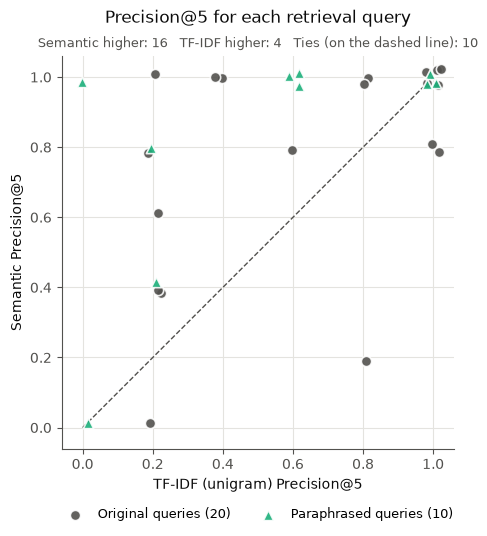

In [21]:
def plot_query_comparison() -> None:
    per_query = paired[["tfidf", "semantic"]].join(query_set.set_index("query_id")["query_origin"])
    better = int((per_query["semantic"] > per_query["tfidf"]).sum())
    worse = int((per_query["semantic"] < per_query["tfidf"]).sum())
    ties = len(per_query) - better - worse

    rng = np.random.default_rng(SEED)
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--", zorder=1)
    for origin, (colour, marker) in ORIGIN_STYLE.items():
        points = per_query[per_query["query_origin"] == origin]
        ax.scatter(points["tfidf"] + rng.uniform(-0.025, 0.025, len(points)),
                   points["semantic"] + rng.uniform(-0.025, 0.025, len(points)),
                   s=55, color=colour, marker=marker, edgecolor="white", linewidth=1.2, alpha=0.9, zorder=2,
                   label=f"{origin.capitalize()} queries ({len(points)})")
    ax.set_xlim(-0.06, 1.06)
    ax.set_ylim(-0.06, 1.06)
    ax.set_xlabel(f"{LABELS['tfidf']} Precision@5")
    ax.set_ylabel("Semantic Precision@5")
    ax.set_aspect("equal")
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
    ax.set_title("Precision@5 for each retrieval query", loc="center", color=INK, pad=24)
    ax.text(0.5, 1.015, f"Semantic higher: {better}   TF-IDF higher: {worse}   Ties (on the dashed line): {ties}",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=9, color=MUTED)
    fig.tight_layout()
    fig.savefig(RESULTS / "figure_query_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()

if final_remaining:
    print("Finish the judgement sheet and rerun 4.4 first.")
else:
    plot_query_comparison()

### 4.5 Apply the Selection Rules

The rule in Section 4 is applied to `retrieve()`, while `search()` keeps TF-IDF word matching, as it is designed for keyword searching.

In [22]:
if final_remaining:
    print("Finish the judgement sheet and rerun 4.4 first.")
else:
    semantic_ms = latency.loc["Semantic", "mean_query_ms"]

    def p5(frame: pd.DataFrame, method: str) -> float:
        return frame.loc[frame["method"] == method, "precision@5"].mean()

    by_category = primary.pivot_table(index="source_label", columns="method", values="precision@5")

    checks = {
        "retrieve()": {
            "Precision@5 gain": round(p5(primary, "semantic") - p5(primary, "tfidf"), 3),
            "required gain": 0.05,
            "at least as good in": f"{(by_category['semantic'] >= by_category['tfidf']).sum()} of {len(by_category)} categories",
            "consistency met": (by_category["semantic"] >= by_category["tfidf"]).sum() >= 6,
            "at least as good (count)": (by_category["semantic"] >= by_category["tfidf"]).sum(),
            "compared": len(by_category),
        },
    }
    selection = pd.DataFrame(checks).T
    selection["semantic mean ms"] = round(semantic_ms, 1)
    selection["speed met"] = semantic_ms <= 200
    selection["gain met"] = selection["Precision@5 gain"].astype(float) >= selection["required gain"].astype(float)
    selection["consistency met"] = selection["consistency met"].astype(bool)
    selection["selected method"] = np.where(
        selection["gain met"] & selection["consistency met"] & selection["speed met"], "semantic", "tfidf"
    )
    selection.index.name = "function"
    display(selection.drop(columns=["at least as good (count)", "compared"]))

    selection_numbers = selection[["Precision@5 gain", "required gain", "at least as good (count)", "compared", "semantic mean ms"]].astype(float)
    selection_numbers["semantic selected"] = (selection["selected method"] == "semantic").astype(int)
    selection_rows = pd.concat(
        [long_rows(selection_numbers.loc[[function]].rename(index={function: "semantic vs tfidf"}), "method_selection", group=function)
         for function in selection_numbers.index],
        ignore_index=True,
    )
    save_rows(RESULTS / "method_comparison.csv", selection_rows, key="experiment")

,Precision@5 gain,required gain,at least as good in,consistency met,semantic mean ms,speed met,gain met,selected method
function,,,,,,,,
retrieve(),0.193,0.05,9 of 10 categories,True,34.0,True,True,semantic


### 4.6 Examples from the Comparison

In this section, examples are shown to explain the results. Each retrieval query is placed in one of four groups by whether each method reaches a Precision@5 of 0.6 (at least 3 of the top 5 results relevant).

- **Groups:** Both reach 0.6, Semantic only (TF-IDF failed), TF-IDF only (Semantic failed) and Neither reaches 0.6.
- **Tables:** each example shows the top three results of both methods, with relevant results shaded.

In [23]:
import html

from IPython.display import Markdown

SUCCESS = 0.6  # at least 3 of the top 5 results relevant
RELEVANT_COLOUR = "#dff3e4"
METHOD_NAMES = {"semantic": "Semantic", "tfidf": "TF-IDF"}
CAPTION_STYLE = [{"selector": "caption", "props": "caption-side: top; text-align: left; padding: 8px 0;"}]

def example_table(query_id: str):
    q = p5.loc[query_id]
    table = {("", "Rank"): [1, 2, 3]}
    for method, name in METHOD_NAMES.items():
        top = final_rankings[(final_rankings["query_id"] == query_id) & (final_rankings["method"] == method)]
        top = top.sort_values("rank").head(3)["doc_id"].tolist()
        table[(name, "Message")] = [full_text[doc_id] for doc_id in top]
        table[(name, "Relevant")] = ["Yes" if judged[(query_id, doc_id)] == 1 else "No" for doc_id in top]
    table = pd.DataFrame(table)

    def shade(frame: pd.DataFrame) -> pd.DataFrame:
        styles = pd.DataFrame("", index=frame.index, columns=frame.columns)
        for name in METHOD_NAMES.values():
            relevant = (frame[(name, "Relevant")] == "Yes").to_numpy()
            for column in ("Message", "Relevant"):
                styles.loc[relevant, (name, column)] = f"background-color: {RELEVANT_COLOUR}; color: black"
        return styles

    messages = [(name, "Message") for name in METHOD_NAMES.values()]
    return (
        table.style.apply(shade, axis=None)
        .format(escape="html", subset=messages)
        .set_properties(subset=messages, **{"white-space": "pre-wrap", "text-align": "left", "min-width": "320px"})
        .hide(axis="index")
        .set_caption(
            f"<b>{query_id}</b> ({q['query_origin']}, {q['source_label']}): {html.escape(q['query_text'])}<br>"
            f"Precision@5: Semantic {q['semantic']:.1f}, TF-IDF {q['tfidf']:.1f}"
        )
        .set_table_styles(CAPTION_STYLE + [
            {"selector": "th.col_heading.level0", "props": "text-align: center;"},
            {"selector": "th.col_heading.level1.col1", "props": "text-align: left;"},
            {"selector": "th.col_heading.level1.col3", "props": "text-align: left;"},
        ])
    )

if final_remaining:
    print("Finish the judgement sheet and rerun 4.4 first.")
else:
    p5 = paired[["semantic", "tfidf"]].join(query_set.set_index("query_id")[["query_origin", "source_label", "query_text"]])
    full_text = final_tfidf["records"].set_index("id")["text_display"]
    judged = final_judgements.set_index(["query_id", "doc_id"])["relevant"]

    groups = {
        "Both reach 0.6": (p5["semantic"] >= SUCCESS) & (p5["tfidf"] >= SUCCESS),
        "Semantic only": (p5["semantic"] >= SUCCESS) & (p5["tfidf"] < SUCCESS),
        "TF-IDF only": (p5["semantic"] < SUCCESS) & (p5["tfidf"] >= SUCCESS),
        "Neither reaches 0.6": (p5["semantic"] < SUCCESS) & (p5["tfidf"] < SUCCESS),
    }
    group_notes = {
        "Both reach 0.6": "both methods reach 0.6 Precision@5.",
        "Semantic only": "semantic retrieval reaches 0.6 Precision@5, while TF-IDF does not.",
        "TF-IDF only": "TF-IDF reaches 0.6 Precision@5, while semantic retrieval does not.",
        "Neither reaches 0.6": "neither method reaches 0.6 Precision@5.",
    }
    summary = pd.DataFrame([
        {
            "Group": name,
            "Queries": int(mask.sum()),
            "Original": int((mask & (p5["query_origin"] == "original")).sum()),
            "Paraphrased": int((mask & (p5["query_origin"] == "paraphrased")).sum()),
            "Query IDs": ", ".join(p5.index[mask]),
        }
        for name, mask in groups.items()
    ])
    display(summary.style.hide(axis="index").set_caption("<b>Retrieval queries in each group</b>").set_table_styles(CAPTION_STYLE))

    gap = p5["semantic"] - p5["tfidf"]
    total = p5["semantic"] + p5["tfidf"]
    picks = {
        "Both reach 0.6": total[groups["Both reach 0.6"]].sort_values(ascending=False),
        "Semantic only": gap[groups["Semantic only"]].sort_values(ascending=False),
        "TF-IDF only": gap[groups["TF-IDF only"]].sort_values(),
        "Neither reaches 0.6": total[groups["Neither reaches 0.6"]].sort_values(),
    }
    for name, order in picks.items():
        display(Markdown(f"**{name}:** {group_notes[name]}"))
        if order.empty:
            display(Markdown("No queries in this group."))
        for query_id in order.index[:2]:
            display(example_table(query_id))

Group,Queries,Original,Paraphrased,Query IDs
Both reach 0.6,17,11,6,"F02, F03, F04, F05, F07, F08, F09, F10, F12, F17, F19, P02, P04, P05, P08, P09, P10"
Semantic only,7,5,2,"F01, F15, F16, F18, F20, P01, P07"
TF-IDF only,1,1,0,F13
Neither reaches 0.6,5,3,2,"F06, F11, F14, P03, P06"


**Both reach 0.6:** both methods reach 0.6 Precision@5.

**Semantic only:** semantic retrieval reaches 0.6 Precision@5, while TF-IDF does not.

**TF-IDF only:** TF-IDF reaches 0.6 Precision@5, while semantic retrieval does not.

**Neither reaches 0.6:** neither method reaches 0.6 Precision@5.

## 5. Duplicates, Filters and Name Search

In this section, three behaviours are checked automatically, without manual judgement:

- **Duplicates (5.1 to 5.3):** the same message is often posted several times with small changes, such as a retweet or an added link. Messages with a TF-IDF similarity of 0.90 or higher are grouped under one result, so copies do not fill the top results. Test copies are made by changing 30 messages in three ways, namely a retweet prefix added, a link added, and capital letters and punctuation changed.
- **Filters (5.4):** each filter should return only the reports it asks for. Filters that apply only to user reports are tested with temporary user reports.
- **Name search (5.5):** a search for a name, such as a place or event, should return the messages containing that name.

### 5.1 Checking Duplicate Threshold

In this section, the threshold of 0.90 is compared with 0.80, 0.85 and 0.95, by the share of test copies caught and the share of other results that would be grouped. The rule is the highest threshold that catches at least 95% of the copies, with at most 1% of other results grouped.

In [24]:
import numpy as np
from scipy import sparse

from models.retrieval import retrieval
from models.retrieval.evaluate import (
    long_rows, save_rows,
    duplicate_groups, duplicate_recall, grouped_share, make_copies, suppression, tfidf_pair_similarity,
)
from models.retrieval.build_index import clean_text, embed_texts, semantic_scores, tfidf_scores
from models.retrieval.retrieval import DUPLICATE_THRESHOLD, rank_scores

if "SELECTED_TFIDF" not in globals():
    comparison_file = pd.read_csv(RESULTS / "method_comparison.csv")
    SELECTED_TFIDF = comparison_file.query(
        "experiment == 'tfidf_settings' and measure == 'selected' and value == 1"
    )["method"].iloc[0]

THRESHOLDS = [0.80, 0.85, 0.90, 0.95]
POTENTIAL_DEPTH = 20

tuning_tfidf = build_tfidf_index(history, ["train"], TFIDF_SETTINGS[SELECTED_TFIDF])
copies = make_copies(tuning_tfidf["records"], n=30, seed=SEED)
copies["similarity"] = tfidf_pair_similarity(tuning_tfidf["vectorizer"], copies["original_text"], copies["copy_text"])

row_of = pd.Series(range(len(tuning_tfidf["records"])), index=tuning_tfidf["records"]["id"])
ungrouped = {
    q.query_id: [
        row_of[r["id"]]
        for r in rank_scores(
            tfidf_scores(q.query_text, tuning_tfidf["vectorizer"], tuning_tfidf["matrix"]),
            POTENTIAL_DEPTH, tuning_tfidf["records"], tuning_tfidf["matrix"], duplicate_threshold=None,
        )
    ]
    for q in tuning_queries.itertuples()
}

rows, flagged = [], []
for threshold in THRESHOLDS:
    grouped = shown = 0
    for query_id, ranked_rows in ungrouped.items():
        count, pairs = grouped_share(ranked_rows, tuning_tfidf["matrix"], threshold)
        grouped += count
        shown += len(ranked_rows)
        if threshold == min(THRESHOLDS):
            flagged += [(query_id, a, b, sim) for a, b, sim in pairs]
    row = {
        "threshold": threshold,
        "copies caught (%)": 100 * (copies["similarity"] >= threshold).mean(),
        "potential grouping rate (%)": 100 * grouped / shown,
    }
    for copy_type, group in copies.groupby("copy_type"):
        row[f"caught: {copy_type} (%)"] = 100 * (group["similarity"] >= threshold).mean()
    rows.append(row)

threshold_check = pd.DataFrame(rows)
meets_rule = threshold_check[
    (threshold_check["copies caught (%)"] >= 95) & (threshold_check["potential grouping rate (%)"] <= 1)
]
threshold_check["meets rule"] = threshold_check["threshold"].isin(meets_rule["threshold"])
CHECKS_FILE = RESULTS / "duplicate_and_filter_checks.csv"
threshold_rows = [
    {"part": "threshold sensitivity", "check": f"{measure} at {row['threshold']:.2f}", "method": "tfidf",
     "value": row[measure], "passed": bool(row["meets rule"]), "details": "passed = threshold meets the rule"}
    for _, row in threshold_check.iterrows()
    for measure in threshold_check.columns.drop(["threshold", "meets rule"])
]
save_rows(CHECKS_FILE, pd.DataFrame(threshold_rows), key="part")
recommended = meets_rule["threshold"].max() if len(meets_rule) else None

texts = tuning_tfidf["records"]["text_display"]
flagged_pairs = pd.DataFrame(
    [(q, round(sim, 3), texts.iloc[a][:100], texts.iloc[b][:100]) for q, a, b, sim in flagged],
    columns=["query_id", "similarity", "kept result", "would be grouped"],
)

In [25]:
CAPTION_STYLE = [{"selector": "caption", "props": "caption-side: top; text-align: left; padding: 8px 0; font-weight: bold;"}]

threshold_view = pd.DataFrame({
    "Threshold": threshold_check["threshold"],
    "Copies caught (%)": threshold_check["copies caught (%)"].round(1),
    "Other results grouped (%)": threshold_check["potential grouping rate (%)"].round(1),
    "Meets rule": threshold_check["meets rule"].map({True: "Yes", False: "No"}),
})
display(
    threshold_view.style.hide(axis="index")
    .format({"Threshold": "{:.2f}", "Copies caught (%)": "{:g}", "Other results grouped (%)": "{:.1f}"})
    .set_caption("Duplicate threshold check")
    .set_table_styles(CAPTION_STYLE)
)

lowest = copies["similarity"].min()
best = f"{recommended:.2f}" if recommended is not None else "none"
print(f"Threshold used in Section 4: {DUPLICATE_THRESHOLD:.2f}. Highest threshold meeting the rule: {best}.")
print(f"Lowest similarity between a copy and its original: {lowest:.3f}"
      + (", so every threshold catches every copy." if lowest >= max(THRESHOLDS) else "."))

text_columns = ["Kept result", "Would be grouped"]
flagged_view = flagged_pairs.sort_values("similarity", ascending=False).rename(columns={
    "query_id": "Query", "similarity": "Similarity", "kept result": "Kept result", "would be grouped": "Would be grouped",
})
display(
    flagged_view.style.hide(axis="index")
    .format({"Similarity": "{:.2f}"})
    .format(escape="html", subset=text_columns)
    .set_properties(subset=text_columns, **{"text-align": "left"})
    .set_caption(f"Other results grouped at {min(THRESHOLDS):.2f} ({len(flagged_view)} pairs)")
    .set_table_styles(CAPTION_STYLE + [{"selector": "th.col_heading", "props": "text-align: left;"}])
)

Threshold,Copies caught (%),Other results grouped (%),Meets rule
0.80,100,4.0,No
0.85,100,4.0,No
0.90,100,4.0,No
0.95,100,4.0,No


Threshold used in Section 4: 0.90. Highest threshold meeting the rule: none.
Lowest similarity between a copy and its original: 1.000, so every threshold catches every copy.


Query,Similarity,Kept result,Would be grouped
T10,1.00,Pray for #Kerala 🙏🙏,Pray for Kerala. #railwayminister
T10,1.00,Pray for Bahamas 🇧🇸🙏🏽🙏🏽🙏🏽,Pray for Bahamas 🇧🇸🙏🏽
T10,1.00,Pray for Bahamas 🇧🇸🙏🏽🙏🏽🙏🏽,RT @nolimitsean: Pray for Bahamas 🙏🏾
T10,0.97,Pray for Bahamas 🇧🇸🙏🏽🙏🏽🙏🏽,RT @Sammiysosa_: pray for the bahamas 🙏🏽😔
T10,0.97,Pray for Bahamas 🇧🇸🙏🏽🙏🏽🙏🏽,Pray for the Bahamas 🙏🏿🙏🏿🇧🇸
T10,0.97,Pray for Bahamas 🇧🇸🙏🏽🙏🏽🙏🏽,Pray for the Bahamas 👏🏼👏🏽🇧🇸👏🏾👏🏿
T10,0.97,Pray for Bahamas 🇧🇸🙏🏽🙏🏽🙏🏽,RT @tracybeanz: Pray for the Bahamas. 😢🙏
T10,0.97,Pray for Bahamas 🇧🇸🙏🏽🙏🏽🙏🏽,RT @kristenhinkson: Pray for the Bahamas 🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼🙏🏼


### 5.2 Finding Copies Already in the Dataset

In this section, copies already in the dataset are used as queries, to test whether each method returns another copy in its top 5 and top 10.

In [26]:
from transformers.utils import logging as transformers_logging

transformers_logging.disable_progress_bar()  

retrieval.reset_index()
retrieval.retrieve("warm-up", 1, method="semantic") 
app = retrieval._get_state()

groups = duplicate_groups(app["records"]).merge(history[["id", "split", "event"]], on="id")
print(f"{groups['group'].nunique()} groups of copies were found ({len(groups)} messages in total).")

def app_rank(method: str):
    return lambda text, k, exclude: retrieval.retrieve(text, k, method=method, exclude_ids=exclude)

duplicate_rows = []
for method in ["tfidf", "semantic"]:
    found = duplicate_recall(groups, app_rank(method))
    duplicate_rows += [
        {"part": "normalised duplicate groups", "method": method, "measure": "member queries", "value": len(found)},
        {"part": "normalised duplicate groups", "method": method, "measure": "Duplicate Recall@5 (%)", "value": 100 * found["found@5"].mean()},
        {"part": "normalised duplicate groups", "method": method, "measure": "Duplicate Recall@10 (%)", "value": 100 * found["found@10"].mean()},
    ]
recall_table = pd.DataFrame(duplicate_rows).pivot(index="method", columns="measure", values="value")
pd.DataFrame({
    "Queries": recall_table["member queries"].astype(int),
    "Duplicate Recall@5 (%)": recall_table["Duplicate Recall@5 (%)"].round(1),
    "Duplicate Recall@10 (%)": recall_table["Duplicate Recall@10 (%)"].round(1),
}).rename(index={"tfidf": "TF-IDF", "semantic": "Semantic"}).rename_axis("Method").loc[["TF-IDF", "Semantic"]]

21 groups of copies were found (52 messages in total).


,Queries,Duplicate Recall@5 (%),Duplicate Recall@10 (%)
Method,,,
TF-IDF,52,100.0,100.0
Semantic,52,94.2,96.2


### 5.3 Comparing Results with and without Grouping

In this section, the 30 original messages are used as queries with grouping (on) or without grouping (off), to count how often their copies repeat in the top 10.

In [27]:
copy_records = pd.DataFrame({
    "id": copies["copy_id"],
    "text_display": copies["copy_text"],
    "board_label": copies["board_label"],
    "source_type": "test_copy",
})
exp_records = pd.concat([app["records"], copy_records], ignore_index=True)
copy_clean = copies["copy_text"].map(clean_text)
exp_matrix = sparse.vstack([app["matrix"], app["vectorizer"].transform(copy_clean)]).tocsr()
exp_embeddings = np.vstack([app["embeddings"], embed_texts(copy_clean, app["model"])])

def experiment_rank(method: str, threshold):
    def rank(text: str, k: int):
        if method == "tfidf":
            scores = tfidf_scores(text, app["vectorizer"], exp_matrix)
        else:
            scores = semantic_scores(text, app["model"], exp_embeddings)
        return rank_scores(scores, k, exp_records, exp_matrix, duplicate_threshold=threshold)
    return rank

duplicate_rows = [row for row in duplicate_rows if not row["part"].startswith("suppression")]  # safe to rerun
for method in ["tfidf", "semantic"]:
    for label, threshold in [("grouping off", None), ("grouping on", DUPLICATE_THRESHOLD)]:
        for measure, value in suppression(copies, experiment_rank(method, threshold)).items():
            duplicate_rows.append({"part": f"suppression, {label}", "method": method, "measure": measure, "value": value})

duplicate_evaluation = pd.DataFrame(duplicate_rows)
save_rows(
    CHECKS_FILE,
    duplicate_evaluation.rename(columns={"measure": "check"}).assign(passed="", details=""),
    key="part",
)
suppression_table = duplicate_evaluation[duplicate_evaluation["part"].str.startswith("suppression")].pivot_table(
    index=["method", "part"], columns="measure", values="value", sort=False
)
pd.DataFrame({
    "Distinct messages in top 10": suppression_table["mean distinct messages in top 10 (up to 10)"],
    "Repeated copies in top 10": suppression_table["mean repeated family members in top 10"],
    "Queries with a repeat (%)": suppression_table["queries with any repeat (%)"],
}).rename(
    index={"tfidf": "TF-IDF", "semantic": "Semantic", "suppression, grouping off": "Off", "suppression, grouping on": "On"}
).rename_axis(["Method", "Grouping"]).map("{:g}".format)

Distinct messages in top 10 Repeated copies in top 10  \
Method   Grouping                                                         
TF-IDF   Off                                7                         3   
         On                                10                         0   
Semantic Off                                7                         3   
         On                                10                         0   

                  Queries with a repeat (%)  
Method   Grouping                            
TF-IDF   Off                            100  
         On                               0  
Semantic Off                            100  
         On                               0

### 5.4 Filter Checks

In this section, each filter is tested with both methods and marked as passed or failed.

In [28]:
QUERY = "Families need drinking water at the shelter"
START, END = pd.Timestamp("2018-08-01", tz="UTC"), pd.Timestamp("2018-09-30", tz="UTC")
filter_checks = []

def record(check: str, method: str, passed: bool, details: str = "") -> None:
    filter_checks.append({"check": check, "method": method, "passed": bool(passed), "details": details})

def lookup(results: list[dict], column: str) -> pd.Series:
    records = retrieval._get_state()["records"].set_index("id")
    return records.loc[[r["id"] for r in results], column]

def ranked_in_order(results: list[dict]) -> bool:
    scores = [r["similarity"] for r in results]
    return all(a >= b for a, b in zip(scores, scores[1:]))

retrieval.reset_index()
for method in ["tfidf", "semantic"]:
    r = retrieval.retrieve(QUERY, 10, filters={"board_label": "requests_or_urgent_needs"}, method=method)
    record("category filter", method, r and all(x["board_label"] == "requests_or_urgent_needs" for x in r), f"{len(r)} results")
    record("ranked order after filtering", method, ranked_in_order(r))

    r = retrieval.search("flooding", filters={"created_after": "2018-08-01", "created_before": "2018-09-30"}, method=method)
    record("time filter", method, r and lookup(r, "created_at").between(START, END).all(), f"{len(r)} results")

    r = retrieval.retrieve(QUERY, 10, filters={"source_type": "humaid_history"}, method=method)
    record("source filter", method, r and all(x["source_type"] == "humaid_history" for x in r), f"{len(r)} results")

    both = {"board_label": "requests_or_urgent_needs", "created_after": "2018-08-01", "created_before": "2018-09-30"}
    r = retrieval.search("water", filters=both, method=method)
    record(
        "category and time together", method,
        r and all(x["board_label"] == "requests_or_urgent_needs" for x in r) and lookup(r, "created_at").between(START, END).all(),
        f"{len(r)} results",
    )

    plain = [x["id"] for x in retrieval.retrieve(QUERY, 10, method=method)]
    empty = [x["id"] for x in retrieval.retrieve(QUERY, 10, filters={"board_label": None, "country": ""}, method=method)]
    record("empty filter values ignored", method, plain == empty)

    try:
        retrieval.retrieve(QUERY, 10, filters={"colour": "red"}, method=method)
        record("unknown filter rejected", method, False, "no error raised")
    except ValueError as error:
        record("unknown filter rejected", method, True, str(error)[:80])

r = retrieval.search("", filters={"board_label": "missing_or_found_people"}, k=20)
times = lookup(r, "created_at")
record(
    "S10 empty-query category filter", "both",
    r and all(x["board_label"] == "missing_or_found_people" and x["similarity"] is None for x in r)
    and times.is_monotonic_decreasing,
    f"{len(r)} results, newest first",
)

test_reports = [
    {"message_id": "test-sydney", "text": "Families in the suburbs need drinking water", "board_label": "requests_or_urgent_needs",
     "status": "unverified", "needs_review": False, "location": {"country": "Australia", "region": "New South Wales", "city": "Sydney"}},
    {"message_id": "test-melbourne", "text": "Water supply cut and residents need drinking water", "board_label": "requests_or_urgent_needs",
     "status": "needs_review", "needs_review": True, "location": {"country": "Australia", "region": "Victoria", "city": "Melbourne"}},
    {"message_id": "test-kl", "text": "Flood shelters need drinking water and food", "board_label": "requests_or_urgent_needs",
     "status": "resolved", "needs_review": False, "location": {"country": "Malaysia", "region": "Selangor", "city": "Kuala Lumpur"}},
]
for report in test_reports:
    retrieval.add_to_index(report)

user_cases = [
    ("country filter (case-insensitive)", {"country": "australia"}, {"test-sydney", "test-melbourne"}),
    ("region filter", {"region": "Victoria"}, {"test-melbourne"}),
    ("city filter", {"city": "Kuala Lumpur"}, {"test-kl"}),
    ("status filter", {"status": "needs_review"}, {"test-melbourne"}),
    ("needs_review filter", {"needs_review": True}, {"test-melbourne"}),
    ("needs_review filter given as text", {"needs_review": "true"}, {"test-melbourne"}),
]
for method in ["tfidf", "semantic"]:
    for check, filters, expected in user_cases:
        found = {x["id"] for x in retrieval.search("drinking water", filters=filters, method=method)}
        record(check, method, found == expected, f"returned {sorted(found)}")

NEW_WORD = "qwertyvale"  # a made-up place name that appears in no historical message
assert not retrieval._get_state()["records"]["clean_text"].str.contains(NEW_WORD).any()
retrieval.add_to_index({"message_id": "test-new-word", "text": f"Sandbags needed near {NEW_WORD.title()} school",
                        "board_label": "requests_or_urgent_needs", "status": "unverified", "needs_review": False})
found = [x["id"] for x in retrieval.search(NEW_WORD.title())]
record("word only in a new user report found by search()", "tfidf", found == ["test-new-word"], f"returned {found}")

retrieval.reset_index()
left = retrieval.search("", filters={"source_type": "user"})
record("temporary reports removed by reset_index()", "both", not left, f"{len(left)} user reports left")

filter_results = pd.DataFrame(filter_checks)
save_rows(CHECKS_FILE, filter_results.assign(part="filters", value=""), key="part")
print(f"Passed {filter_results['passed'].sum()} of {len(filter_results)} checks")
with pd.option_context("display.max_colwidth", None):
    display(filter_results)

Passed 29 of 29 checks


,check,method,passed,details
0,category filter,tfidf,True,10 results
1,ranked order after filtering,tfidf,True,
2,time filter,tfidf,True,20 results
3,source filter,tfidf,True,10 results
4,category and time together,tfidf,True,20 results
5,empty filter values ignored,tfidf,True,
6,unknown filter rejected,tfidf,True,"Unknown filter 'colour'. Supported filters: board_label, source_type, status, ne"
7,category filter,semantic,True,10 results
8,ranked order after filtering,semantic,True,
9,time filter,semantic,True,20 results


### 5.5 Name Search

In this section, 20 names from each group (by how many messages contain the name) are searched, and the share of the top 10 results containing the name is measured. The names are not printed, as names appearing in few messages may belong to private individuals.

In [29]:
import re
from collections import Counter

import numpy as np
from transformers.utils import logging as transformers_logging

from models.retrieval import retrieval
from models.retrieval.evaluate import save_rows

transformers_logging.disable_progress_bar()  

retrieval.reset_index()
retrieval.warm_up("semantic")
state = retrieval._get_state()
records = state["records"]
analyse = state["vectorizer"].build_analyzer()  # the same word splitting as TF-IDF
message_words = records["clean_text"].map(lambda text: set(analyse(text)))
words_by_id = dict(zip(records["id"], message_words))
messages_with = Counter(word for words in message_words for word in words)

# Candidate names: words written in title case in at least 90% of their uses (first word of a message,
# hashtags and @usernames left out).
WORD = re.compile(r"(?<![#@\w])[A-Za-z]{4,}(?!\w)")
title_case, uses = Counter(), Counter()
for text in records["text_display"]:
    text = re.sub(r"^\s*RT\s+@\w+:?\s*", "", text)
    for position, match in enumerate(WORD.finditer(text)):
        if position == 0:
            continue
        word = match.group()
        uses[word.lower()] += 1
        title_case[word.lower()] += word.istitle()
names = sorted(word for word in uses if title_case[word] / uses[word] >= 0.9)

BANDS = [("1 message", 1, 1), ("2 to 5 messages", 2, 5), ("6 to 20 messages", 6, 20),
         ("21 to 100 messages", 21, 100), ("over 100 messages", 101, None)]
rng = np.random.default_rng(SEED)
name_rows = []
for band, low, high in BANDS:
    pool = [w for w in names if messages_with[w] >= low and (high is None or messages_with[w] <= high)]
    name_sample = rng.choice(pool, size=min(20, len(pool)), replace=False)
    for method in ["tfidf", "semantic"]:
        found, empty = [], 0
        for name in name_sample:
            results = retrieval.search(name, k=10, method=method)
            shown = dict.fromkeys(i for r in results for i in [r["id"], *r["duplicate_ids"]])
            possible = min(10, messages_with[name])
            found.append(min(sum(name in words_by_id[i] for i in shown), possible) / possible)
            empty += not results
        name_rows += [
            {"experiment": "name_search", "group": band, "subgroup": "all", "method": method, "measure": measure, "value": value}
            for measure, value in [("names in collection", len(pool)), ("names searched", len(name_sample)),
                                   ("name found@10", float(np.mean(found))), ("searches with no result", empty)]
        ]

name_results = pd.DataFrame(name_rows)
save_rows(RESULTS / "method_comparison.csv", name_results, key="experiment")
name_table = name_results.pivot_table(index="group", columns=["measure", "method"], values="value", sort=False)
pd.DataFrame({
    "Names in collection": name_table[("names in collection", "tfidf")].astype(int),
    "Names searched": name_table[("names searched", "tfidf")].astype(int),
    "Found@10 (TF-IDF)": name_table[("name found@10", "tfidf")].round(2),
    "Found@10 (semantic)": name_table[("name found@10", "semantic")].round(2),
}).rename_axis("Group")

,Names in collection,Names searched,Found@10 (TF-IDF),Found@10 (semantic)
Group,,,,
1 message,6607,20,1.0,0.35
2 to 5 messages,2610,20,1.0,0.45
6 to 20 messages,727,20,1.0,0.31
21 to 100 messages,326,20,1.0,0.49
over 100 messages,112,20,1.0,0.60


> **Key Findings of Section 5**: Both methods handle duplicates well, all filters work, and only TF-IDF reliably finds names. That supports using TF-IDF for search().